# Makkah Retail Sales — 03: Apply Review Decisions

Applies only the decisions a person recorded in `data/review/decisions.csv`. Issues without a decision are left untouched and listed as **pending**, so the output is clearly marked as provisional until the review is complete.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from dq import checks

INTERIM, REVIEW, CLEAN = Path("data/interim"), Path("data/review"), Path("data/clean")
CLEAN.mkdir(parents=True, exist_ok=True)

cities = pd.read_csv(INTERIM / "cities_weekly.csv", parse_dates=["starting_date"])
sectors = pd.read_csv(INTERIM / "sectors_weekly.csv", parse_dates=["starting_date"])
dec = pd.read_csv(REVIEW / "decisions.csv", dtype=str).fillna("")

ALLOWED = {"name_mismatch": {"map", "separate"}, "outlier": {"keep", "exclude"}, "missing_weeks": {"document"}}
bad = dec[(dec.decision != "") & ~dec.apply(lambda r: r.decision in ALLOWED.get(r.check, set()), axis=1)]
assert bad.empty, f"Unknown decisions:\n{bad[['issue_id', 'check', 'decision']]}"

pending = dec[dec.decision == ""]
print(f"Decided: {len(dec) - len(pending)}  |  Pending: {len(pending)}")
pending[["issue_id", "severity", "check", "key", "detail"]]

Decided: 212  |  Pending: 0


,issue_id,severity,check,key,detail


## 1. City names

In [2]:
maps = dec.query("check == 'name_mismatch' and decision == 'map'")
name_map = dict(zip(maps.key, maps.value))
cities["city"] = cities["city"].replace(name_map)
print("Mapped:", name_map or "nothing yet")

Mapped: {'Hail': 'Hayel', 'Khobar': 'Al-Khubar', 'Madina': 'Al-Madinah'}


## 2. Unusual weeks

In [3]:
ex = dec.query("check == 'outlier' and decision == 'exclude'").key.str.split(" \\| ", expand=True)
ex_keys = set(zip(ex[0], pd.to_datetime(ex[1]))) if len(ex) else set()
cities["excluded"] = [(c, d) in ex_keys for c, d in zip(cities.city, cities.starting_date)]
sectors["excluded"] = [(s, d) in ex_keys for s, d in zip(sectors.sectors, sectors.starting_date)]
print("Weeks flagged as excluded:", int(cities.excluded.sum() + sectors.excluded.sum()))

Weeks flagged as excluded: 0


## 3. Makkah series with the Islamic calendar

In [4]:
cal = checks.calendar_flags(cities.starting_date)
makkah = (cities.query("city == 'Makkah'").merge(cal, on="starting_date", how="left")
          .sort_values("starting_date").reset_index(drop=True))
cols = ["starting_date", "sales_m_sar", "transactions_m", "source", "covid_period", "excluded",
        "hijri_year", "ramadan_days", "last_10_ramadan", "eid_fitr", "hajj", "eid_adha"]
makkah = makkah[cols]
makkah.query("last_10_ramadan")[["starting_date", "hijri_year", "sales_m_sar"]]

,starting_date,hijri_year,sales_m_sar
0,2020-05-10,1441,114.412
1,2020-05-17,1441,157.691
51,2021-05-02,1442,534.251
52,2021-05-09,1442,391.185
101,2022-04-17,1443,649.812
102,2022-04-24,1443,926.710
103,2022-05-01,1443,386.688
152,2023-04-09,1444,806.821
153,2023-04-16,1444,707.988
202,2024-03-24,1445,819.394


## 4. Save

In [5]:
status = "provisional (review pending)" if len(pending) else "final (review complete)"
makkah.to_csv(CLEAN / "makkah_weekly.csv", index=False)
cities.to_csv(CLEAN / "cities_weekly.csv", index=False)
sectors.to_csv(CLEAN / "sectors_weekly.csv", index=False)
(CLEAN / "STATUS.txt").write_text(f"{status}\npending issues: {len(pending)}\n")
print("Saved —", status)

Saved — final (review complete)


## 5. First look

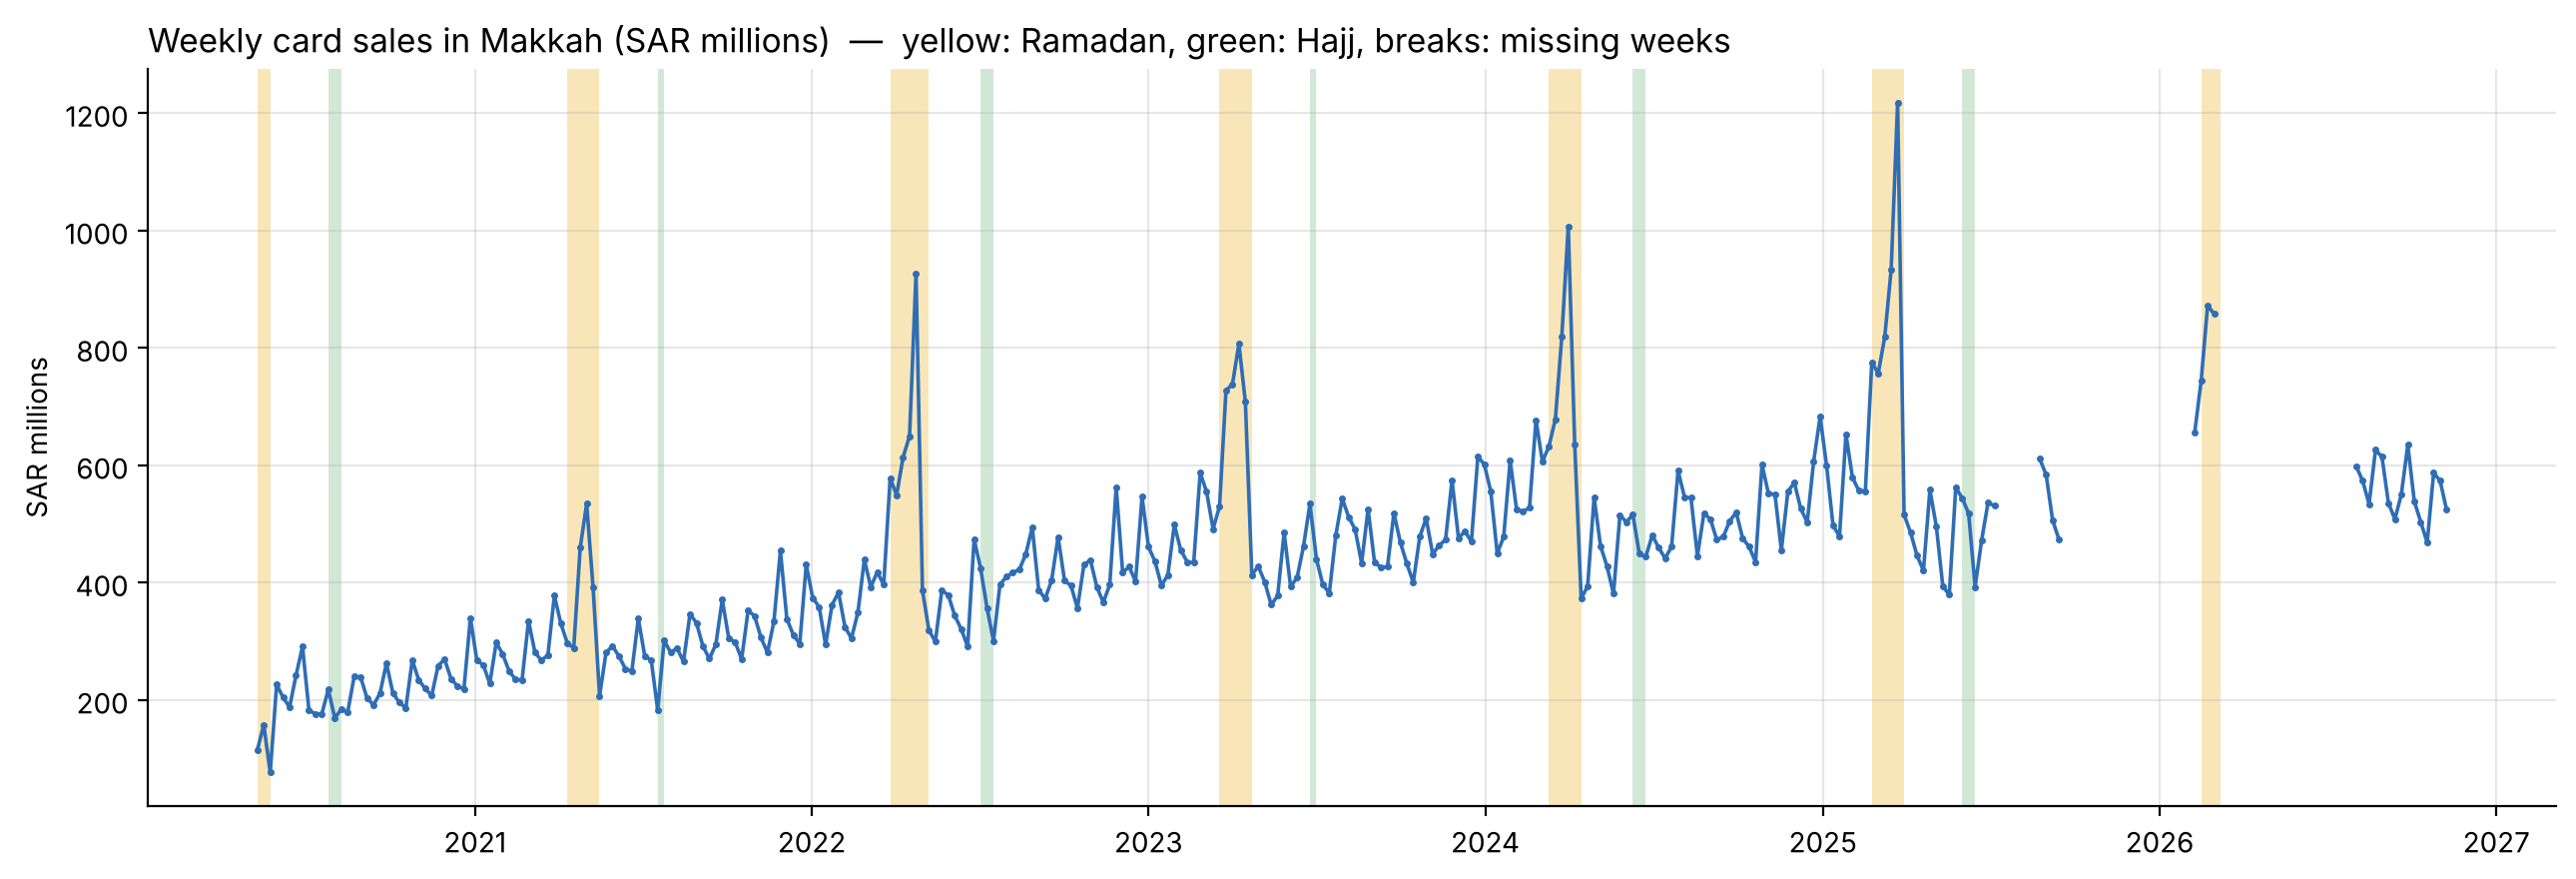

Typical week: 427M SAR  |  Last 10 days of Ramadan: 757M SAR  (1.8x)


In [6]:
full = pd.date_range(makkah.starting_date.min(), makkah.starting_date.max(), freq="W-SUN")
series = makkah.set_index("starting_date").sales_m_sar.reindex(full)  # NaN breaks the line at missing weeks
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(series.index, series.values, color="#2f6db5", lw=1.3, marker=".", ms=3)
for flag, color in [("ramadan_days", "#f2c14e"), ("hajj", "#8fc79a")]:
    for d in makkah.loc[makkah[flag].astype(bool), "starting_date"]:
        ax.axvspan(d, d + pd.Timedelta(days=7), color=color, alpha=0.4, lw=0)
ax.set_title("Weekly card sales in Makkah (SAR millions)  —  yellow: Ramadan, green: Hajj, breaks: missing weeks", loc="left")
ax.set_ylabel("SAR millions"); ax.grid(alpha=0.3); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(CLEAN / "makkah_weekly.png", dpi=150); plt.show()

normal = makkah.query("ramadan_days == 0 and not hajj and not eid_adha and not covid_period and not excluded")
base, peak = normal.sales_m_sar.median(), makkah.query("last_10_ramadan and not covid_period").sales_m_sar.median()
print(f"Typical week: {base:,.0f}M SAR  |  Last 10 days of Ramadan: {peak:,.0f}M SAR  ({peak / base:.1f}x)")